In [1]:
!pip install xgboost joblib

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/creditcard.csv")
X = df.drop(columns=["Class"])
y = df["Class"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_tr.shape, X_te.shape)
print("fraud in train:", y_tr.sum(), "| fraud in test:", y_te.sum())

(227845, 30) (56962, 30)
fraud in train: 394 | fraud in test: 98


In [3]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_tr)
X_tr_s = sc.transform(X_tr)
X_te_s = sc.transform(X_te)

In [4]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_tr_s, y_tr)
proba = clf.predict_proba(X_te_s)[:, 1]
print("done")

done


In [5]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix

print("PR-AUC:", round(average_precision_score(y_te, proba), 4))
pred = (proba >= 0.5).astype(int)
print(confusion_matrix(y_te, pred))
print(classification_report(y_te, pred, digits=4))

PR-AUC: 0.719
[[55478  1386]
 [    8    90]]
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962



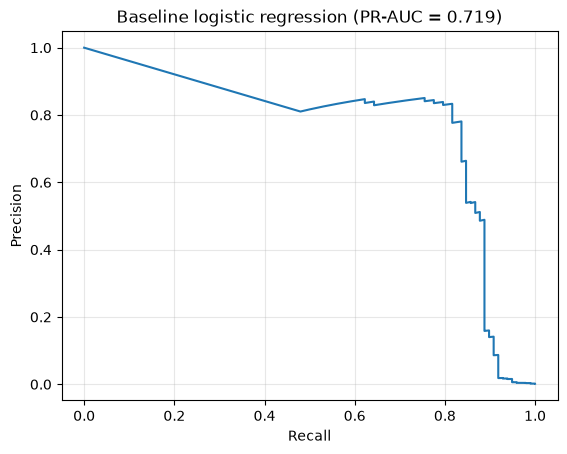

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

p, r, t = precision_recall_curve(y_te, proba)
plt.plot(r, p)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Baseline logistic regression (PR-AUC = 0.719)")
plt.grid(alpha=0.3)
plt.show()

In [7]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(clf, "../models/baseline_lr.joblib")
joblib.dump(sc, "../models/scaler.joblib")
print("saved")

saved
